# NN2: Next-Hour Bike Rental Demand Forecasting

## 1. Introduction

This notebook develops the second neural network (NN2) in our two-stage bike-sharing demand forecasting pipeline.

NN2 is a multilayer perceptron (MLP) designed to predict the number of bike rentals in the next hour using:

- Predicted weather conditions (temperature, humidity, and windspeed) from NN1.
- The observed bike rental count from the previous hour.
- Calendar features associated with the target hour.

The model produces a single continuous output representing the predicted rental count.

We first implement and validate the NN2 training pipeline using a temporary weather-persistence baseline. The final evaluation will use NN1-generated weather predictions and compare the two weather-input strategies under a controlled experimental setup.

## 2. Data Preparation

We use the UCI Bike Sharing Dataset (`hour.csv`) and follow the same chronological train, validation, and test split as NN1.

For each target hour, we prepare the previous-hour rental count, target-hour calendar features, and weather inputs. During initial development, we use the latest observed weather conditions as a temporary baseline.

All preprocessing parameters that require fitting will be learned from the training data only to avoid data leakage.

In [ ]:
#Import libraries for NN2 data preparation
from pathlib import Path

import numpy as np
import pandas as pd

In [ ]:
# Load the hourly bike-sharing dataset
df = pd.read_csv(Path("../hour.csv"))
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [ ]:
#create a timestamp for each hourly record
df["timestamp"] = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")

#sort records in chronological order
df = df.sort_values("timestamp").reset_index(drop=True)
display(df[["dteday", "hr", "timestamp"]].head())

,dteday,hr,timestamp
0,2011-01-01,0,2011-01-01 00:00:00
1,2011-01-01,1,2011-01-01 01:00:00
2,2011-01-01,2,2011-01-01 02:00:00
3,2011-01-01,3,2011-01-01 03:00:00
4,2011-01-01,4,2011-01-01 04:00:00


The following cell uses weather persistence as a temporary substitute for NN1 predictions. For each target hour, the weather conditions from the previous hour are used as the predicted weather inputs.

Need to be changed after we have NN1's weather predictions.

In [14]:
# Create previous-hour features
df["cnt_lag1"] = df["cnt"].shift(1)
df["pred_temp"] = df["temp"].shift(1)
df["pred_hum"] = df["hum"].shift(1)
df["pred_windspeed"] = df["windspeed"].shift(1)

# Keep only records with a valid previous hour
df["hour_gap"] = df["timestamp"].diff()
df = df[df["hour_gap"] == pd.Timedelta(hours=1)].copy()

display(df[["timestamp", "cnt", "cnt_lag1", "pred_temp"]].head())

,timestamp,cnt,cnt_lag1,pred_temp
1,2011-01-01 01:00:00,40,16.0,0.24
2,2011-01-01 02:00:00,32,40.0,0.22
3,2011-01-01 03:00:00,13,32.0,0.22
4,2011-01-01 04:00:00,1,13.0,0.24
5,2011-01-01 05:00:00,1,1.0,0.24


The dataset provides five original calendar variables，If we do want to match the 12-input NN2 design described in our proposal，we need to further encode these 5 features.

In [ ]:
#select calendar features for NN2
calendar_cols = ["hr", "mnth", "weekday", "workingday", "holiday"]

#Check calendar features
display(df[calendar_cols].head())

,hr,mnth,weekday,workingday,holiday
0,0,1,6,0,0
1,1,1,6,0,0
2,2,1,6,0,0
3,3,1,6,0,0
4,4,1,6,0,0


In [ ]:
# Split data by date
train_data = df[df["timestamp"] < "2012-05-01"]
val_data = df[
    (df["timestamp"] >= "2012-05-01") &
    (df["timestamp"] < "2012-09-01")
]
test_data = df[df["timestamp"] >= "2012-09-01"]
print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Test:", test_data.shape)

Training: (11468, 23)
Validation: (2952, 23)
Test: (2883, 23)


In [ ]:
weather_cols = ["pred_temp", "pred_hum", "pred_windspeed"]

input_cols = weather_cols + ["cnt_lag1"] + calendar_cols
target_col = "cnt"

# Select input features and target
X_train = train_data[input_cols].copy()
X_val = val_data[input_cols].copy()
X_test = test_data[input_cols].copy()
y_train = train_data[[target_col]].copy()
y_val = val_data[[target_col]].copy()
y_test = test_data[[target_col]].copy()

#Scale using training statistics only
for col in input_cols:
    mean = X_train[col].mean()
    std = X_train[col].std()

    if std == 0:
        std = 1
    X_train[col] = (X_train[col] - mean) / std
    X_val[col] = (X_val[col] - mean) / std
    X_test[col] = (X_test[col] - mean) / std

# Scale the target
target_mean = y_train["cnt"].mean()
target_std = y_train["cnt"].std()
y_train["cnt"] = (y_train["cnt"] - target_mean) / target_std
y_val["cnt"] = (y_val["cnt"] - target_mean) / target_std
y_test["cnt"] = (y_test["cnt"] - target_mean) / target_std
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)


X_train: (11468, 9)
y_train: (11468, 1)


In [ ]:
import torch
import torch.nn as nn

#convert data to PyTorch tensors
X_train = torch.tensor(X_train.values, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.float32)

X_val = torch.tensor(X_val.values, dtype=torch.float32)
y_val = torch.tensor(y_val.values, dtype=torch.float32)

X_test = torch.tensor(X_test.values, dtype=torch.float32)
y_test = torch.tensor(y_test.values, dtype=torch.float32)
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

X_train: torch.Size([11468, 9])
y_train: torch.Size([11468, 1])


## 3. NN2 Model Architecture

We use a simple multilayer perceptron (MLP) to predict next-hour bike rental demand.

The network has nine input features, two hidden layers with 32 and 16 neurons, and one output representing the predicted rental count.

In [ ]:
# Define NN2 MLP
class RentalDemandMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(9, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )
    def forward(self, x):
        return self.network(x)

#create the model
model = RentalDemandMLP()
print(model)


RentalDemandMLP(
  (network): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [20]:
# Test the model with five training samples
sample_X = X_train[:5]

sample_predictions = model(sample_X)

print("Input shape:", sample_X.shape)
print("Output shape:", sample_predictions.shape)

Input shape: torch.Size([5, 9])
Output shape: torch.Size([5, 1])


## 4. Model Training

We train NN2 using Mean Squared Error (MSE) loss and the Adam optimizer. The model learns to predict standardized next-hour rental counts from the input features.

This initial model uses weather persistence inputs and will be retrained when NN1 predictions become available.

Epoch: 10 Train Loss: 0.8566 Val Loss: 2.5195
Epoch: 20 Train Loss: 0.7578 Val Loss: 2.2671
Epoch: 30 Train Loss: 0.6573 Val Loss: 1.9872
Epoch: 40 Train Loss: 0.5673 Val Loss: 1.6969
Epoch: 50 Train Loss: 0.4926 Val Loss: 1.4212
Epoch: 60 Train Loss: 0.4317 Val Loss: 1.1928
Epoch: 70 Train Loss: 0.381 Val Loss: 1.0236
Epoch: 80 Train Loss: 0.3397 Val Loss: 0.8994
Epoch: 90 Train Loss: 0.3086 Val Loss: 0.8064
Epoch: 100 Train Loss: 0.288 Val Loss: 0.7435


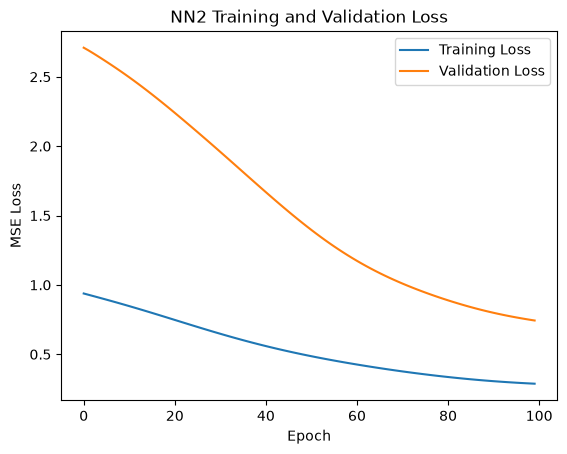

In [21]:
#Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 100

#Train NN2
train_losses = []
val_losses = []

for epoch in range(epochs):
    # Training
    model.train()

    optimizer.zero_grad()
    predictions = model(X_train)
    loss = criterion(predictions, y_train)

    loss.backward()
    optimizer.step()

    #Validation
    model.eval()

    with torch.no_grad():
        val_predictions = model(X_val)
        val_loss = criterion(val_predictions, y_val)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    if (epoch + 1) % 10 == 0:
        print("Epoch:", epoch + 1,
              "Train Loss:", round(loss.item(), 4),
              "Val Loss:", round(val_loss.item(), 4))

#Loss Curve
import matplotlib.pyplot as plt

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("NN2 Training and Validation Loss")
plt.legend()
plt.show()

## 5. Model Evaluation

We evaluate NN2 on the validation set using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).
Predictions are converted back to the original rental count scale before calculating the errors.

This evaluation uses temporary weather persistence inputs rather than NN1 predictions.

In [23]:
#Predict on validation data
model.eval()

with torch.no_grad():
    val_predictions = model(X_val)

#Convert predictions back to rental counts
val_predictions = val_predictions.numpy() * target_std + target_mean
actual_values = y_val.numpy() * target_std + target_mean

#Calculate MAE and RMSE
mae = np.mean(np.abs(val_predictions - actual_values))
rmse = np.sqrt(np.mean((val_predictions - actual_values) ** 2))

print("Validation MAE:", round(mae, 2))
print("Validation RMSE:", round(rmse, 2))

# Compare actual and predicted rental counts
results = pd.DataFrame({
    "Actual": actual_values.flatten(),
    "Predicted": val_predictions.flatten()
})
display(results.head(10))

Validation MAE: 86.29
Validation RMSE: 126.48


,Actual,Predicted
0,34.999997,84.505484
1,20.999999,56.744260
2,8.000000,45.363434
3,2.999998,35.969621
4,8.000000,28.814385
5,16.999996,36.218858
6,26.000001,43.452758
7,169.000000,52.266627
8,557.000012,170.545821
9,349.000005,364.882647


## 6. NN1 Integration (Future Work)

The current NN2 model uses weather persistence as a temporary substitute for NN1 predictions.

Once the NN1 model is finalized, we will replace the persistence weather inputs with NN1-generated weather predictions and retrain NN2.

The NN2 architecture and training pipeline can remain largely unchanged.

## 7. Controlled Weather-Input Comparison (Future Work)

After NN1 integration, we will compare NN2 rental predictions using two different weather inputs:

- Weather predictions generated by NN1.
- Weather persistence predictions based on the previous hour.

We will use the same trained NN2 model and evaluation samples for both inputs, then compare rental prediction errors using MAE and RMSE.

This experiment will help determine whether NN1 weather forecasting improves rental demand prediction compared with weather persistence.